# Experiment No. 9 — Data Storytelling and Business Insight Generation using Interactive Visualizations

- **Name:** Abhigyan Dubey
- **Course & Branch:** B.TECH CSE
- **CUID:** CU24250059
- **SUBJECT:** Mastery in Data Analytics and Visualizations and Career Advancement
- **SEM & Section:** 5th SEM, "B"

**Aim:** To create a compelling data-driven story by analyzing a real-world dataset, developing meaningful visualizations, and presenting actionable business insights to support strategic decision-making.

**Dataset:** Restaurant Tips (Sales) Dataset, loaded via `seaborn.load_dataset('tips')` — no download needed.

---

## Steps 1–2: Select dataset and define the business problem

**Dataset:** 244 restaurant bills with `total_bill`, `tip`, `sex`, `smoker`, `day`, `time` and party `size`.

**Business problem:** *When and from whom does the restaurant earn the most revenue and tips, and what should management do to increase them?*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = sns.load_dataset('tips')
df['tip_pct'] = df['tip'] / df['total_bill'] * 100   # tip as % of bill

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

Shape: (244, 8)
Missing values: 0


,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


## Step 3: Exploratory Data Analysis

In [2]:
print(df[['total_bill', 'tip', 'size', 'tip_pct']].describe().round(2))
print()
print(df[['total_bill', 'tip', 'size', 'tip_pct']].corr().round(2))

       total_bill     tip    size  tip_pct
count      244.00  244.00  244.00   244.00
mean        19.79    3.00    2.57    16.08
std          8.90    1.38    0.95     6.11
min          3.07    1.00    1.00     3.56
25%         13.35    2.00    2.00    12.91
50%         17.80    2.90    2.00    15.48
75%         24.13    3.56    3.00    19.15
max         50.81   10.00    6.00    71.03

            total_bill   tip  size  tip_pct
total_bill        1.00  0.68  0.60    -0.34
tip               0.68  1.00  0.49     0.34
size              0.60  0.49  1.00    -0.14
tip_pct          -0.34  0.34 -0.14     1.00


## Step 5: Key Performance Indicators (KPIs)

In [3]:
kpis = {
    "Total Revenue ($)": df['total_bill'].sum(),
    "Total Tips ($)": df['tip'].sum(),
    "Number of Bills": len(df),
    "Average Bill ($)": df['total_bill'].mean(),
    "Average Tip (%)": df['tip_pct'].mean(),
    "Average Party Size": df['size'].mean(),
}
pd.DataFrame(kpis, index=["Value"]).T.round(2)

,Value
Total Revenue ($),4827.77
Total Tips ($),731.58
Number of Bills,244.00
Average Bill ($),19.79
Average Tip (%),16.08
Average Party Size,2.57


## Steps 4 & 6: Visualizations arranged as a story

**Story flow:** *When do we earn?* → *Which service is stronger?* → *Where is the sweet spot?* → *What drives tips?*

### Chart 1 — When do we earn? (Revenue by day)

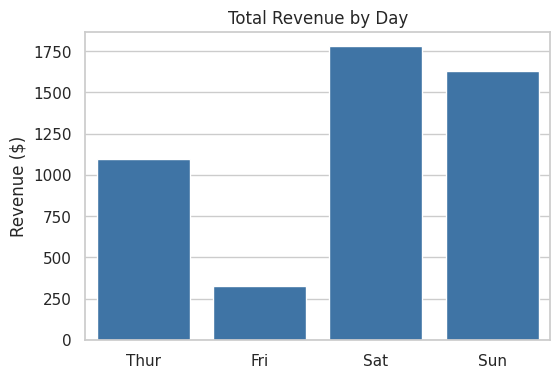

In [4]:
rev_day = df.groupby('day', observed=True)['total_bill'].sum().reindex(['Thur', 'Fri', 'Sat', 'Sun'])

plt.figure(figsize=(6, 4))
sns.barplot(x=rev_day.index, y=rev_day.values, color="#2E75B6")
plt.title("Total Revenue by Day")
plt.ylabel("Revenue ($)")
plt.xlabel("")
plt.show()

### Chart 2 — Which service is stronger? (Lunch vs Dinner)

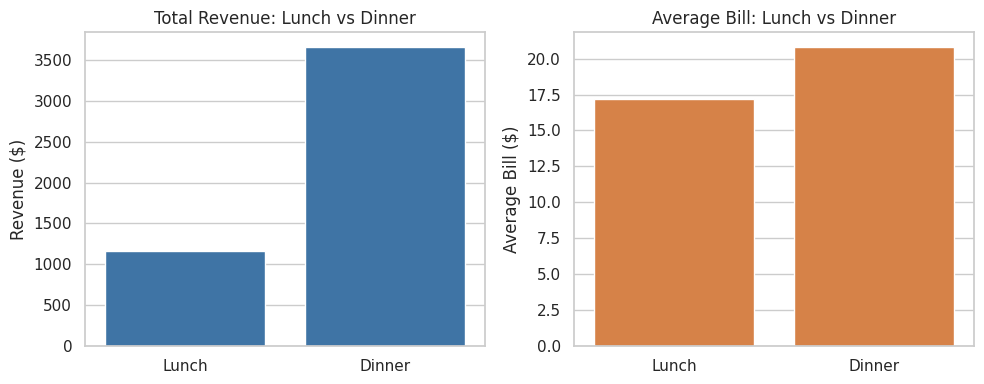

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(data=df, x='time', y='total_bill', estimator='sum', errorbar=None, color="#2E75B6", ax=axes[0])
axes[0].set_title("Total Revenue: Lunch vs Dinner")
axes[0].set_ylabel("Revenue ($)")
axes[0].set_xlabel("")

sns.barplot(data=df, x='time', y='total_bill', errorbar=None, color="#ED7D31", ax=axes[1])
axes[1].set_title("Average Bill: Lunch vs Dinner")
axes[1].set_ylabel("Average Bill ($)")
axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

### Chart 3 — Where is the sweet spot? (Heatmap: average bill by day and time)

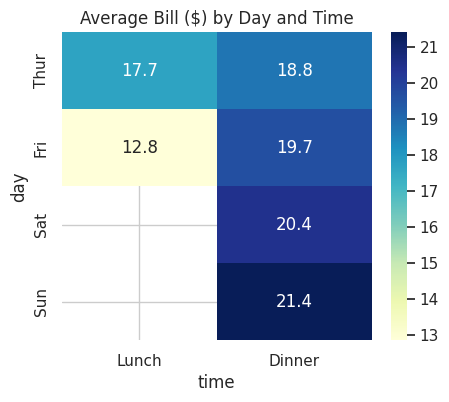

In [6]:
pivot = df.pivot_table(index='day', columns='time', values='total_bill', aggfunc='mean', observed=True)

plt.figure(figsize=(5, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Average Bill ($) by Day and Time")
plt.show()

### Chart 4 — What drives tips? (Bill vs tip, and tip % by party size)

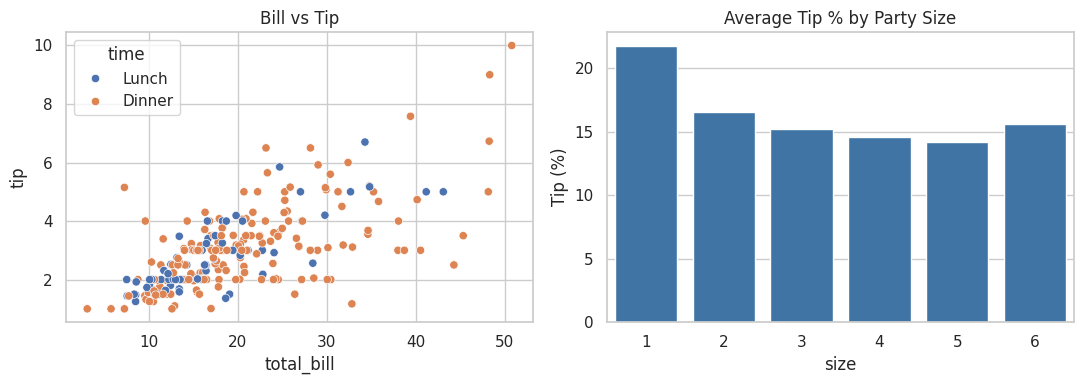

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df, x='total_bill', y='tip', hue='time', ax=axes[0])
axes[0].set_title("Bill vs Tip")

sns.barplot(data=df, x='size', y='tip_pct', errorbar=None, color="#2E75B6", ax=axes[1])
axes[1].set_title("Average Tip % by Party Size")
axes[1].set_ylabel("Tip (%)")
plt.tight_layout(); plt.show()

### Supporting numbers

In [8]:
print(df.groupby('day', observed=True).agg(bills=('total_bill', 'count'), revenue=('total_bill', 'sum'),
                                           avg_bill=('total_bill', 'mean'), avg_tip_pct=('tip_pct', 'mean')).round(2))
print()
print(df.groupby('time', observed=True).agg(bills=('total_bill', 'count'), revenue=('total_bill', 'sum'),
                                            avg_bill=('total_bill', 'mean'), avg_tip_pct=('tip_pct', 'mean')).round(2))
print()
print(df.groupby('size').agg(bills=('tip', 'count'), avg_bill=('total_bill', 'mean'), avg_tip_pct=('tip_pct', 'mean')).round(2))

      bills  revenue  avg_bill  avg_tip_pct
day                                        
Thur     62  1096.33     17.68        16.13
Fri      19   325.88     17.15        16.99
Sat      87  1778.40     20.44        15.32
Sun      76  1627.16     21.41        16.69

        bills  revenue  avg_bill  avg_tip_pct
time                                         
Lunch      68  1167.47     17.17        16.41
Dinner    176  3660.30     20.80        15.95

      bills  avg_bill  avg_tip_pct
size                              
1         4      7.24        21.73
2       156     16.45        16.57
3        38     23.28        15.22
4        37     28.61        14.59
5         5     30.07        14.15
6         4     34.83        15.62


## Step 7: Key insights (what the charts tell us)

1. **Weekends and Thursday carry the business:** Saturday (≈ $1,778) and Sunday (≈ $1,627) earn the most, Thursday follows (≈ $1,096), and Friday is very weak (≈ $326, only 19 bills).
2. **Dinner is the main revenue source:** Dinner brings ≈ $3,660 (≈ 76% of revenue) with a higher average bill (≈ $20.80 vs ≈ $17.17 at lunch).
3. **Sweet spot:** Sunday and Saturday dinner have the highest average bills (≈ $21.4 and ≈ $20.4). Friday lunch has the lowest (≈ $12.9).
4. **Tips grow with the bill but the percentage falls:** Bill and tip are strongly correlated (0.68), but tip % drops as party size grows (≈ 16.6% for 2 people → ≈ 14–15% for 4–5).
5. **Risk / performance gap:** Heavy dependence on dinner and weekends; Friday and lunch are under-used.

## Step 8: Recommendations

- **Boost Friday and lunch** with offers such as combo meals or happy hours, since these slots have the most unused capacity.
- **Protect weekend dinner:** keep full staffing and quality, and run upselling (starters, desserts, drinks) to raise the average bill further.
- **Target larger parties** (3–4 people) with group deals — their bills are much higher (≈ $23–29), even though tip % is slightly lower.
- **Train staff on service quality**, because tip % (≈ 16% on average) is the direct measure of customer satisfaction.
- **Track KPIs weekly** (revenue, average bill, tip %, party size) on a dashboard to see whether the actions work.

*(Limitation: only 244 bills, so results are indicative, not final.)*

## Steps 9–10: Presenting the story and why storytelling matters

**Step 9:** The complete data story is presented in this Jupyter Notebook as: *Problem → Data → KPIs → Charts → Insights → Recommendations*. The same charts can be turned into slides or a Tableau / Power BI dashboard.

**Step 10:** Effective storytelling turns charts into decisions. It helps non-technical stakeholders understand *what happened, why it matters and what to do next*, builds trust in the analysis, reduces misinterpretation, and makes it more likely that insights are actually acted on.

## Questions

**Q1. What is data storytelling? How is it different from data visualization?**

**Ans:** Data storytelling combines data analysis, visualization and narrative to explain *what the data means* and recommend actions. Data visualization only presents the data graphically (charts and graphs). Visualization shows the facts; storytelling explains their significance and what to do about them.

**Q2. Why is storytelling important in business analytics and decision-making?**

**Ans:** Decision-makers are often non-technical and don't act on raw numbers. A story gives context, highlights what matters, makes insights memorable, builds trust, and moves stakeholders from information to action.

**Q3. What are the essential components of an effective data story?**

**Ans:** (1) Clear business problem/objective, (2) reliable data and analysis, (3) effective visualizations, (4) a narrative flow (context → findings → insight), (5) key insights/KPIs, and (6) actionable recommendations, all tailored to the audience.

**Q4. How do Key Performance Indicators (KPIs) enhance business reporting?**

**Ans:** KPIs are measurable values (e.g., total revenue, average bill, tip %) that show performance against goals. They focus reports on what matters, allow tracking over time and comparison with targets, and make progress easy to understand at a glance.

**Q5. Why should visualizations be arranged in a logical sequence while presenting analytical findings?**

**Ans:** A logical order (problem → analysis → findings → recommendations) guides the audience step by step, so each chart builds on the previous one. It avoids confusion, keeps the message coherent and leads naturally to the conclusion.

**Q6. What factors should be considered while selecting visualizations for a business presentation?**

**Ans:** The audience and their technical level, the type of data (categorical, numerical, time-based), the message to convey (comparison, trend, distribution, relationship), simplicity and clarity, accuracy (no misleading scales) and readable design (labels, colours, titles).

**Q7. Explain how dashboards and storytelling complement each other in Business Intelligence.**

**Ans:** Dashboards give a real-time, at-a-glance view of KPIs and let users explore data, but they don't explain it. Storytelling adds the narrative, interpretation and recommendations. Together, dashboards supply the evidence and storytelling supplies the meaning and the call to action.

**Q8. What challenges may arise while communicating analytical insights to non-technical stakeholders?**

**Ans:** Technical jargon, information overload, differing levels of data literacy, misinterpretation of statistics (e.g., correlation vs causation), resistance to findings that contradict beliefs, and lack of clear business relevance. These are overcome with simple language, clear visuals and a focus on actions.

**Q9. Give two real-world examples where data storytelling has influenced business or policy decisions.**

**Ans:** (1) **Florence Nightingale's "rose" diagram** showed that most soldier deaths in the Crimean War came from preventable disease, which pushed reforms in military hospital sanitation. (2) **John Snow's 1854 cholera map** of London linked deaths to the Broad Street water pump, leading authorities to remove the pump handle and advancing public-health policy.

**Q10. How can effective data storytelling improve strategic planning and organizational performance?**

**Ans:** It aligns teams around the same facts, helps leaders spot opportunities and risks quickly, supports evidence-based (not intuition-based) decisions, speeds up approval of actions, and makes it easy to track whether strategies are working — leading to better planning and performance.